# **PRAKTIKUM 1**

**Langkah 0 - Persiapan Lingkungan**

In [22]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

**Langkah 1 - Memuat Data**

In [23]:
df = pd.read_csv('../Data/jakarta_house.csv')

df.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


**Langkah 2 - Inspeksi Data**

In [24]:
# Pengecekan Dimensi
df.shape

(10000, 9)

In [25]:
# Pengecekan Tipe data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  str    
 3   city           10000 non-null  str    
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      9997 non-null   float64
 8   building_area  9995 non-null   float64
dtypes: float64(2), int64(5), str(2)
memory usage: 937.6 KB


In [26]:
# Pengecekan Jumlah Data Null
df.isnull().sum()

index            0
price            0
district         0
city             0
bed_rooms        0
bath_rooms       0
carport          0
land_area        3
building_area    5
dtype: int64

In [27]:
# Ringkasan Nilai Statistik
df.describe()

,index,price,bed_rooms,bath_rooms,carport,land_area,building_area
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,9997.000000,9995.000000
mean,5000.50000,1.004029e+10,4.253500,3.521300,1.578900,296.610183,319.962481
std,2886.89568,2.004519e+10,3.176609,2.900136,1.743467,502.921686,357.676034
min,1.00000,1.850000e+06,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2500.75000,2.500000e+09,3.000000,2.000000,1.000000,100.000000,139.000000
50%,5000.50000,4.500000e+09,4.000000,3.000000,1.000000,177.000000,230.000000
75%,7500.25000,9.800000e+09,5.000000,4.000000,2.000000,335.000000,400.000000
max,10000.00000,9.000000e+11,63.000000,63.000000,31.000000,17714.000000,15331.000000


**Langkah 3 - Inspeksi Visual**

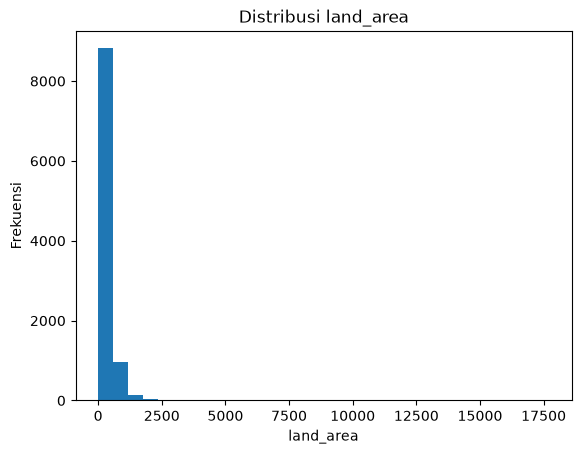

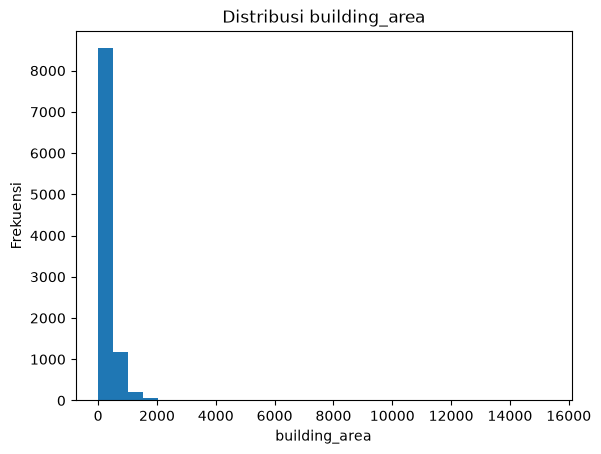

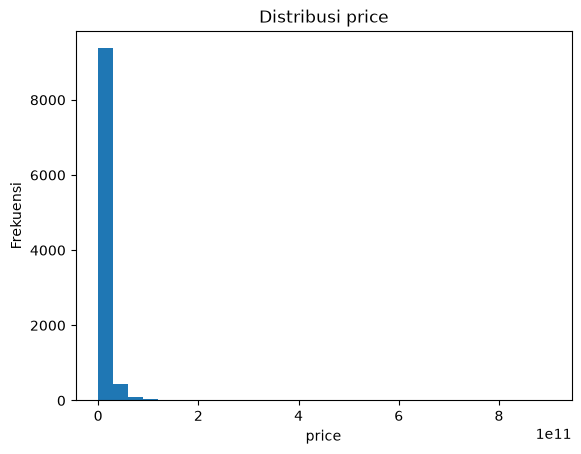

In [28]:
# Inspeksi Distribusi Data
num_cols = ['land_area', 'building_area', 'price']
for col in num_cols:
    plt.figure()
    plt.hist(df[col].dropna(), bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col); plt.ylabel('Frekuensi')
    plt.show()

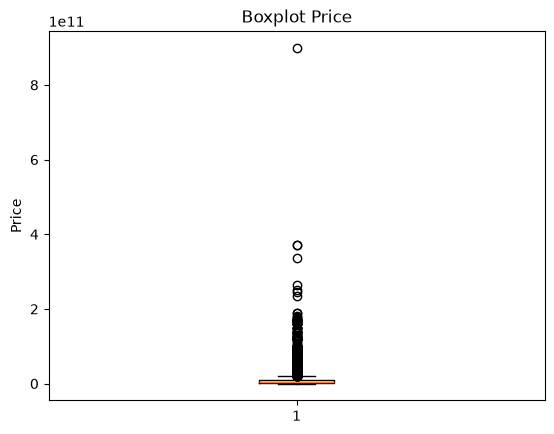

In [29]:
# Inspeksi Outlier
plt.figure()
plt.boxplot(df['price'].dropna(), vert=True)
plt.title('Boxplot Price')
plt.ylabel('Price')
plt.show()

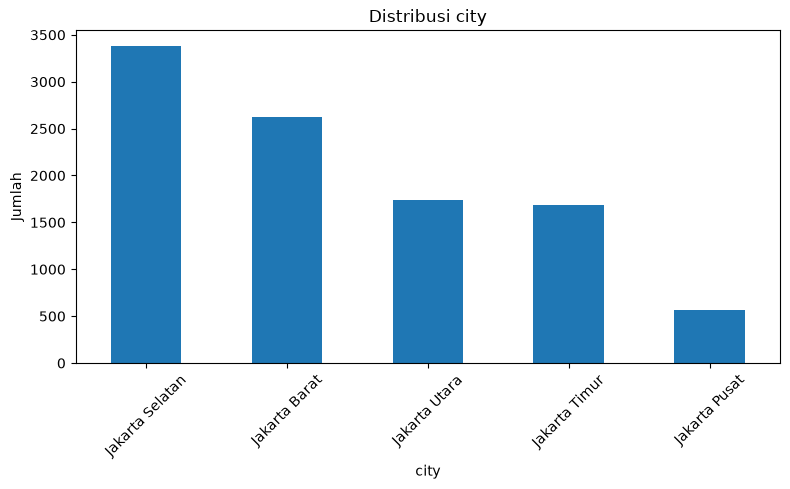

In [30]:
# Inspeksi Komposisi Variabel Kualitatif
plt.figure(figsize=(8, 5))
df['city'].value_counts(dropna=False).plot(kind='bar')
plt.title('Distribusi city')
plt.xlabel('city')
plt.ylabel('Jumlah')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

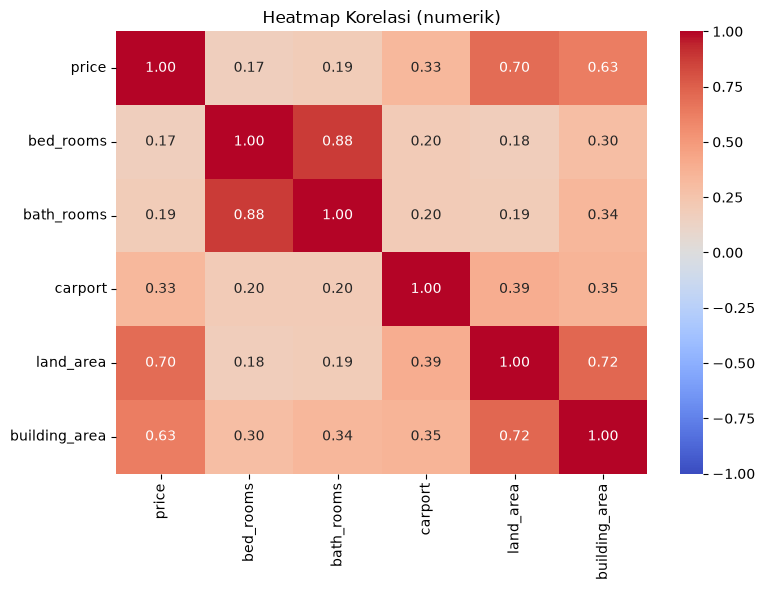

In [31]:
# Inspeksi Korelasi Heatmap
import seaborn as sns

num_only = df.select_dtypes(include=[np.number])
if 'index' in num_only.columns:
    num_only = num_only.drop(columns=['index'])
corr = num_only.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt=".2f")
plt.title('Heatmap Korelasi (numerik)')
plt.tight_layout()
plt.show()

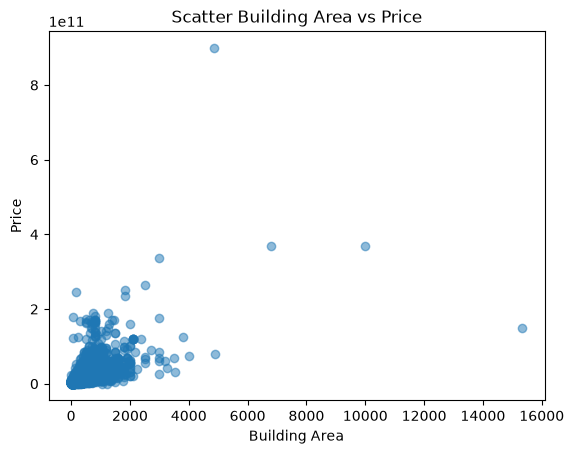

In [32]:
# Inspeksi Korelasi Scatter Plot
plt.figure()
plt.scatter(df['building_area'], df['price'], alpha=0.5)
plt.xlabel('Building Area')
plt.ylabel('Price')
plt.title('Scatter Building Area vs Price')
plt.show()

# **PRAKTIKUM 2**

**Langkah 0 - Persiapan**

Sudah saya lakukan di praktikum 1 diatas

**Langkah 1 - Memuat Data**

Sudah saya lakukan di praktikum 1 diatas

**Langkah 2 - Inspeksi Data**

Sudah saya lakukan di praktikum 1 diatas

**Langkah 3 - Data Imputation**

In [33]:
# land_area - mean
df['land_area'] = df['land_area'].fillna(df['land_area'].mean())

# building_area - median
df['building_area'] = df['building_area'].fillna(df['building_area'].median())

# city - modus (sebagai contoh imputasi data kategorikal)
df['city'] = df['city'].fillna(df['city'].mode()[0])

**Langkah 4 - Validasi Hasil**

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  str    
 3   city           10000 non-null  str    
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      10000 non-null  float64
 8   building_area  10000 non-null  float64
dtypes: float64(2), int64(5), str(2)
memory usage: 937.6 KB


In [35]:
df.isnull().sum()

index            0
price            0
district         0
city             0
bed_rooms        0
bath_rooms       0
carport          0
land_area        0
building_area    0
dtype: int64

# **PRAKTIKUM 3**

**Langkah 1 - Load Data**

In [36]:
# Memuat data jakarta_house yang sudah bersih (atau memuat ulang dan imputasi)
df = pd.read_csv('../Data/jakarta_house.csv')
df['land_area'] = df['land_area'].fillna(df['land_area'].mean())
df['building_area'] = df['building_area'].fillna(df['building_area'].median())

df.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


**Langkah 2 - Slice Data**

In [37]:
# Memilih subset fitur untuk pemodelan (target: price, kategorikal: city, district, numerik: building_area, land_area)
df = df[['price', 'city', 'district', 'building_area', 'land_area']]
df.head()

,price,city,district,building_area,land_area
0,5900000000,Jakarta Barat,Citra Garden,350.0,250.0
1,2700000000,Jakarta Barat,Jelambar,225.0,100.0
2,2200000000,Jakarta Barat,Jelambar,140.0,60.0
3,1900000000,Jakarta Barat,Jelambar,120.0,60.0
4,2100000000,Jakarta Barat,Tanjung Duren,108.0,56.0


**Langkah 3 - Encoding**

In [38]:
le = LabelEncoder() # membuat objek dari LabelEncoder
df['city'] = le.fit_transform(df['city']) # proses encoding
df['district'] = le.fit_transform(df['district']) # proses encoding

**Langkah 4 - Verifikasi Hasil**

In [39]:
df.head()

,price,city,district,building_area,land_area
0,5900000000,0,39,350.0,250.0
1,2700000000,0,74,225.0,100.0
2,2200000000,0,74,140.0,60.0
3,1900000000,0,74,120.0,60.0
4,2100000000,0,234,108.0,56.0


**Langkah 5 - Standarisasi**

In [40]:
std = StandardScaler()
df['building_area'] = std.fit_transform(df[['building_area']])
df['land_area'] = std.fit_transform(df[['land_area']])

**Langkah 6 - Verifikasi Hasil Standarisasi**

In [41]:
df.head()

,price,city,district,building_area,land_area
0,5900000000,0,39,0.084129,-0.092697
1,2700000000,0,74,-0.265448,-0.391014
2,2200000000,0,74,-0.503161,-0.470565
3,1900000000,0,74,-0.559093,-0.470565
4,2100000000,0,234,-0.592653,-0.478520
